## 💭 Ausgangspunkt: die Frage, die diese Version beantwortet

**Beobachtung nach v5:** Die Fraktale sind weg, aber die Bilder sind nicht fotoscharf, und PCA 512 liegt noch vorn. v5 hatte nur 1.500 Schritte auf der CPU.

**Frage:** Liegt das am Modell oder an der kurzen Zeit, und wie viel sichtbare Schärfe ist danach möglich?

**Status dieses Notebooks:** vollständig ausgeführt. Es lädt die Gewichte der Läufe aus `v6_experiments/runs/`. Trainiert wurde mit `v6_experiments/exp.py` auf einer RTX 3050 Ti, die Befehle stehen im Abschnitt zum Training.

---

## 📝 Changelog: v6 gegenüber v5

| # | Einstellung | v5 | v6 | Warum |
|---|---|---|---|---|
| 1 | Training | 30.000 Bilder, 1.500 Schritte | **45.000 Bilder, 11.250 Schritte** | Die offene Frage aus v5 |
| 2 | Breite | 32/64/128 | **64/128/256** | Bremst die Modellgröße noch? Lauf B1 sagt: ja, etwas |
| 3 | Prüfer | L1 + SSIM | **zwei Modelle:** Treue (B1) und Natürlichkeit (B3, mit GAN) | Der Zielkonflikt bleibt so messbar |
| 4 | Adversarial-Prüfer | keiner | **PatchGAN, Hinge-Loss, Gewicht 0,01, ab 30 % der Schritte** | Gewicht 0,1 war instabil |
| 5 | Messung | MSE, SSIM, Raster, Spektrum | **zusätzlich KID und VGG-Abstand** | Natürlichkeit messbar machen |
| 6 | Auswahl | Testset | **Validierung** | Das Testset bleibt für die Endauswertung |

**Abweichungen vom Plan:**
- VGG läuft in B2 und B4 auf 48×48 statt 64×64 Pixeln, sonst reicht der Grafikspeicher nicht.
- Der GAN-Lauf startete nach einem Fehlversuch neu. Gewicht 0,1 ließ `val_loss` von 0,0317 auf bis zu 0,3096 steigen.
- B3 wurde auf der CPU aus den gespeicherten Gewichten ausgewertet, weil die Auswertung am Laufende auf der GPU scheiterte.

**Grenzen:**
- Jeder Vergleich beruht auf einem einzelnen Lauf.
- Der VGG-Abstand ist nicht LPIPS: gleiche Idee, aber ohne dessen gelernte Gewichte.
- Die Details von Real-ESRGAN sind erfunden und auf CIFAR-10 nicht überprüfbar.

# Autoencoder auf CIFAR-10

## Aufgabenbeschreibung

Wir haben gesehen, wie man einen Autoencoder für die Graustufenbilder des Fashion-MNIST-Datensatzes baut. In dieser Übung baust du einen für den CIFAR-10-Datensatz (https://www.cs.toronto.edu/~kriz/cifar.html). Dieser Datensatz enthält **Farbbilder** mit einer Auflösung von 32x32.

### Vorbereitung


In [1]:
import matplotlib.pyplot as plt


def sample_batch(dataset):
    batch = dataset.take(1).get_single_element()
    if isinstance(batch, tuple):
        batch = batch[0]
    return batch.numpy()


def display(
    images, n=10, size=(20, 3), cmap="gray_r", as_type="float32", save_to=None
):
    """
    Zeigt n Bilder aus jedem der übergebenen Arrays an.
    """
    if images.max() > 1.0:
        images = images / 255.0
    elif images.min() < 0.0:
        images = (images + 1.0) / 2.0

    plt.figure(figsize=size)
    for i in range(n):
        _ = plt.subplot(1, n, i + 1)
        plt.imshow(images[i].astype(as_type), cmap=cmap)
        plt.axis("off")

    if save_to:
        plt.savefig(save_to)
        print(f"\nSaved to {save_to}")

    plt.show()


In [2]:
import json
import subprocess
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import keras
import tensorflow as tf
from tensorflow.keras import datasets, models

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# v6: Architektur, Losses und Training liegen in exp.py, damit Notebook und Läufe denselben Code nutzen.
sys.path.insert(0, "./v6_experiments")
import exp

I0000 00:00:1793548481.901670 2410005 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793548482.640488 2410005 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 0. Parameter <a name="parameters"></a>

In [3]:
IMAGE_SIZE = 32
CHANNELS = 3
BATCH_SIZE = 100

# 8x8 x LATENT_CHANNELS: 512 Dimensionen wie in v5.
LATENT_CHANNELS = 8
EMBEDDING_DIM = 8 * 8 * LATENT_CHANNELS
WIDTHS = (64, 128, 256)

TRAIN_SAMPLES = 45000
VAL_SAMPLES = 5000
EPOCHS = 25

# Die beiden Modelle dieses Notebooks.
FIDELITY_TAG = "B1"       # beste Treue
NATURAL_TAG = "B3"  # bester Lauf mit Adversarial-Prüfer

# False lädt die Gewichte aus v6_experiments/runs. True trainiert neu, das dauert auf der GPU rund 30 Minuten je Lauf.
RETRAIN = False
RUNS = Path("./v6_experiments/runs")

## 1. Daten vorbereiten <a name="prepare"></a>

In [4]:
# Daten laden
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

In [5]:
# Daten vorverarbeiten

def preprocess(imgs):
    """
    Normalisiert die Bilder und bringt sie in die richtige Form
    """
    imgs = imgs.astype("float32") / 255.0
    imgs = imgs.reshape(len(imgs),imgs.shape[1],imgs.shape[2],3)
    return imgs


x_train = preprocess(x_train)
x_test = preprocess(x_test)

In [6]:
# Die Validierung kommt aus dem Trainingsset, das Testset dient nur der Endauswertung.
x_val = x_train[-VAL_SAMPLES:]
x_fit = x_train[:TRAIN_SAMPLES]

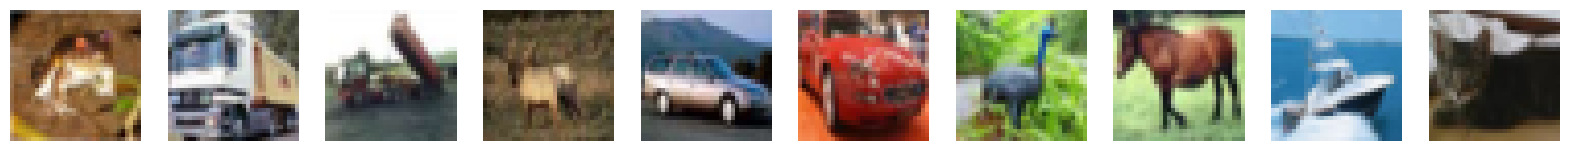

In [7]:
# Einige Bilder aus dem Trainingsset anzeigen
display(x_train)

## 2. Autoencoder aufbauen <a name="build"></a>

In [8]:
# Architektur wie v5 (exp.build_v5), aber doppelt so breit: 3,86 statt 0,97 Mio. Parameter.
def build_autoencoder():
    return exp.build_v5(LATENT_CHANNELS, list(WIDTHS))

build_autoencoder().summary()

Model: "v5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalization │ (None, 32, 32,    │        128 │ conv2d[0][0]      │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ group_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │     36,928 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_1[0][0]    │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ group_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     36,928 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ conv2d[0][0],     │
│                     │ 64)               │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │     73,856 │ add[0][0]         │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_3[0][0]    │
│ (GroupNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 16, 16,    │          0 │ group_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │    147,584 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_4[0][0]    │
│ (GroupNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 16, 16,    │          0 │ group_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │    147,584 │ activation_3[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 16,    │          0 │ conv2d_3[0][0], 

 Total params: 3,864,715 (14.74 MB)

 Trainable params: 3,864,715 (14.74 MB)

 Non-trainable params: 0 (0.00 B)

## 2a. Die beiden Prüfer

- **Treue-Modell:** `L1 + 0,2 × (1 − SSIM)` wie in v5.
- **Natürlichkeits-Modell:** zusätzlich ein Adversarial-Prüfer. Ein kleines zweites Netz (PatchGAN) lernt, echte Bildausschnitte von nachgemalten zu unterscheiden. Der Autoencoder lernt, es zu täuschen. Der Code steht in `exp.GanTrainer` und `exp.build_discriminator`.

### Gewichtung der Note: wo festgelegt, wo verwendet

Die Gewichte stehen in `v6_experiments/exp.py`. Die Befehle der Läufe stehen im Abschnitt 3, dort mit `[Gewicht]` markiert.

| Gewicht | Wert | Festgelegt | So ermittelt | Verwendet |
|---|---|---|---|---|
| SSIM-Teil | 0,2 | `--ssim-weight`, Zeile 470 | Unverändert aus v5, keine Testreihe | `l1_ssim_terms`, Zeile 125 |
| VGG-Teil (nur B2, B4) | 0,1 | `--vgg-weight`, Zeile 471 | Standardwert, keine Testreihe | `make_r2_loss`, Zeile 154 |
| Glättung (nur B2, B4) | 0,01 | `--tv-weight`, Zeile 472 | Standardwert, keine Testreihe | `make_r2_loss`, Zeile 157 |
| GAN-Teil (nur B3, B4) | 0,01 | `--gan-weight` im Befehl, Zeile 476 | Im Versuch: Startwert 0,1 aus `PLAN_v6.md` kippte, 0,01 blieb stabil. Zwischenwerte nicht getestet | `GanTrainer.train_step`, Zeile 224 |

**Beleg für das GAN-Gewicht:** Mit 0,1 stieg `val_loss` nach dem Zuschalten von 0,0317 auf 0,3096, der Lauf wurde abgebrochen (`v6_experiments/runs/B3_w0.1_abgebrochen.log`). Mit 0,01 stieg er nur kurz von 0,0312 auf 0,0392 und endete bei 0,0291 (`v6_experiments/runs/B3_history.json`). `val_loss` enthält bei diesen Läufen nur L1 und SSIM.

**Der Fälschungs-Erkenner** hat eine eigene Note (Hinge-Loss, Zeile 221) und einen eigenen Optimierer (Adam, Lernrate 0,0002, `beta_1=0.5`, Zeile 342). Er und der GAN-Teil sind in den ersten 30 % der Schritte abgeschaltet (`--gan-start`, Zeile 477, also 3.375 von 11.250 Schritten). Danach lernen beide Netze im selben Schritt je einmal.

**Anteile am Ende:**

| Lauf | L1 | SSIM | VGG | Glättung | GAN |
|---|---|---|---|---|---|
| B1 | 69,8 % | 30,2 % | | | |
| B2 | 60,2 % | 26,6 % | 9,8 % | 3,4 % | |
| B3 | 62,5 % | 27,8 % | | | 9,7 % |

Anteile: erste 1.000 Testbilder, berechnet mit `v6_experiments/note_terms.py`, Werte in `v6_experiments/runs/note_terms.json`. Der GAN-Anteil kommt aus dem Trainingslog des letzten Durchgangs, weil der Erkenner nicht gespeichert wurde.

## 3. Autoencoder trainieren <a name="train"></a>

In [9]:
# [Gewicht] Das GAN-Gewicht steht hier als --gan-weight, die übrigen Gewichte sind Standardwerte in exp.py.
COMMANDS = {
    "B1": "R3 --r3-loss R1 --epochs 25 --widths 64 128 256 --tag B1",
    "B2": "R3 --r3-loss R2 --vgg-size 48 --epochs 25 --widths 64 128 256 --tag B2",
    "B3": "R3 --r3-loss R1 --gan-weight 0.01 --epochs 25 --widths 64 128 256 --tag B3",
    "B4": "R3 --r3-loss R2 --vgg-size 48 --gan-weight 0.01 --epochs 25 --widths 64 128 256 --tag B4",
}
if RETRAIN:
    for tag in (FIDELITY_TAG, NATURAL_TAG):
        subprocess.run([sys.executable, "exp.py", *COMMANDS[tag].split()], cwd="./v6_experiments", check=True)


def load_run(tag):
    model = build_autoencoder()
    model.load_weights(RUNS / f"{tag}.weights.h5")
    model.compile(jit_compile=False)
    return model


autoencoder = load_run(FIDELITY_TAG)
natural = load_run(NATURAL_TAG)
encoder = keras.Model(autoencoder.input, autoencoder.get_layer("latent").output)

## 4. Rekonstruieren mit dem Autoencoder <a name="reconstruct"></a>

In [10]:
n_to_predict = 5000
example_images = x_test[:n_to_predict]
example_labels = y_test[:n_to_predict]

Example real images


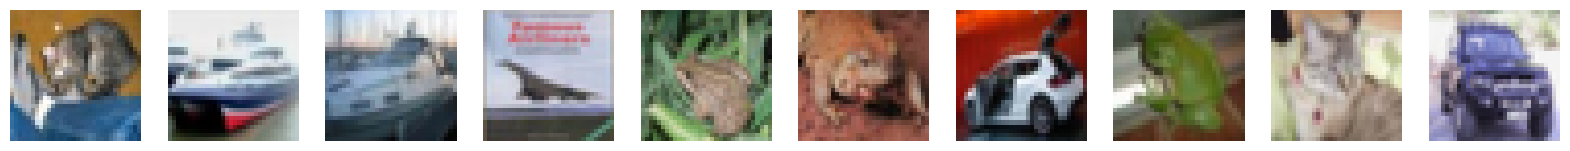

Reconstructions, Treue-Modell


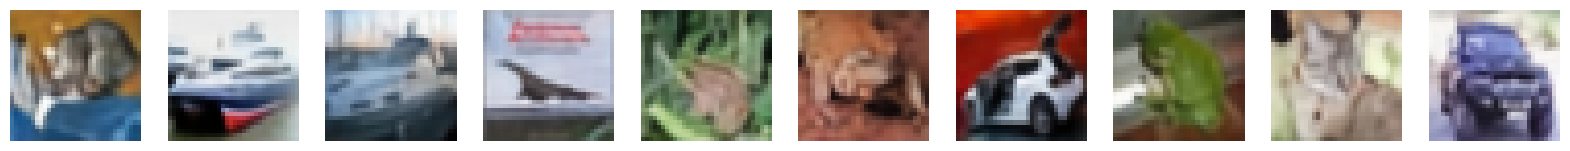

Reconstructions, Natürlichkeits-Modell


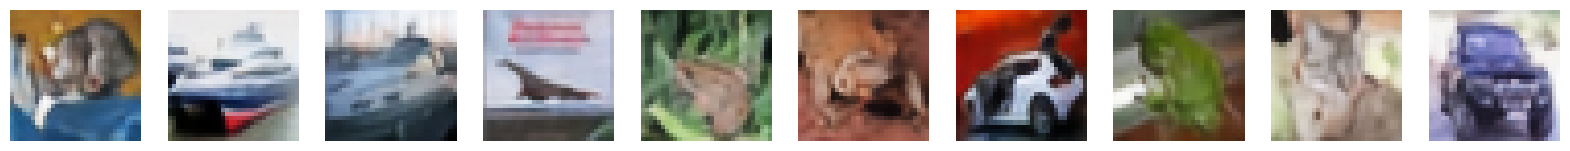

In [11]:
predictions = autoencoder.predict(x_test, batch_size=500, verbose=0)
predictions_natural = natural.predict(x_test, batch_size=500, verbose=0)

print("Example real images")
display(x_test)
print("Reconstructions, Treue-Modell")
display(predictions)
print("Reconstructions, Natürlichkeits-Modell")
display(predictions_natural)

### 4a. Muster sichtbar machen: Zoom und Differenz

4-fach mit Nearest Neighbor vergrößert, damit kein Weichzeichnen der Anzeige Muster verdeckt. Die Differenz zum Original ist 4-fach verstärkt.

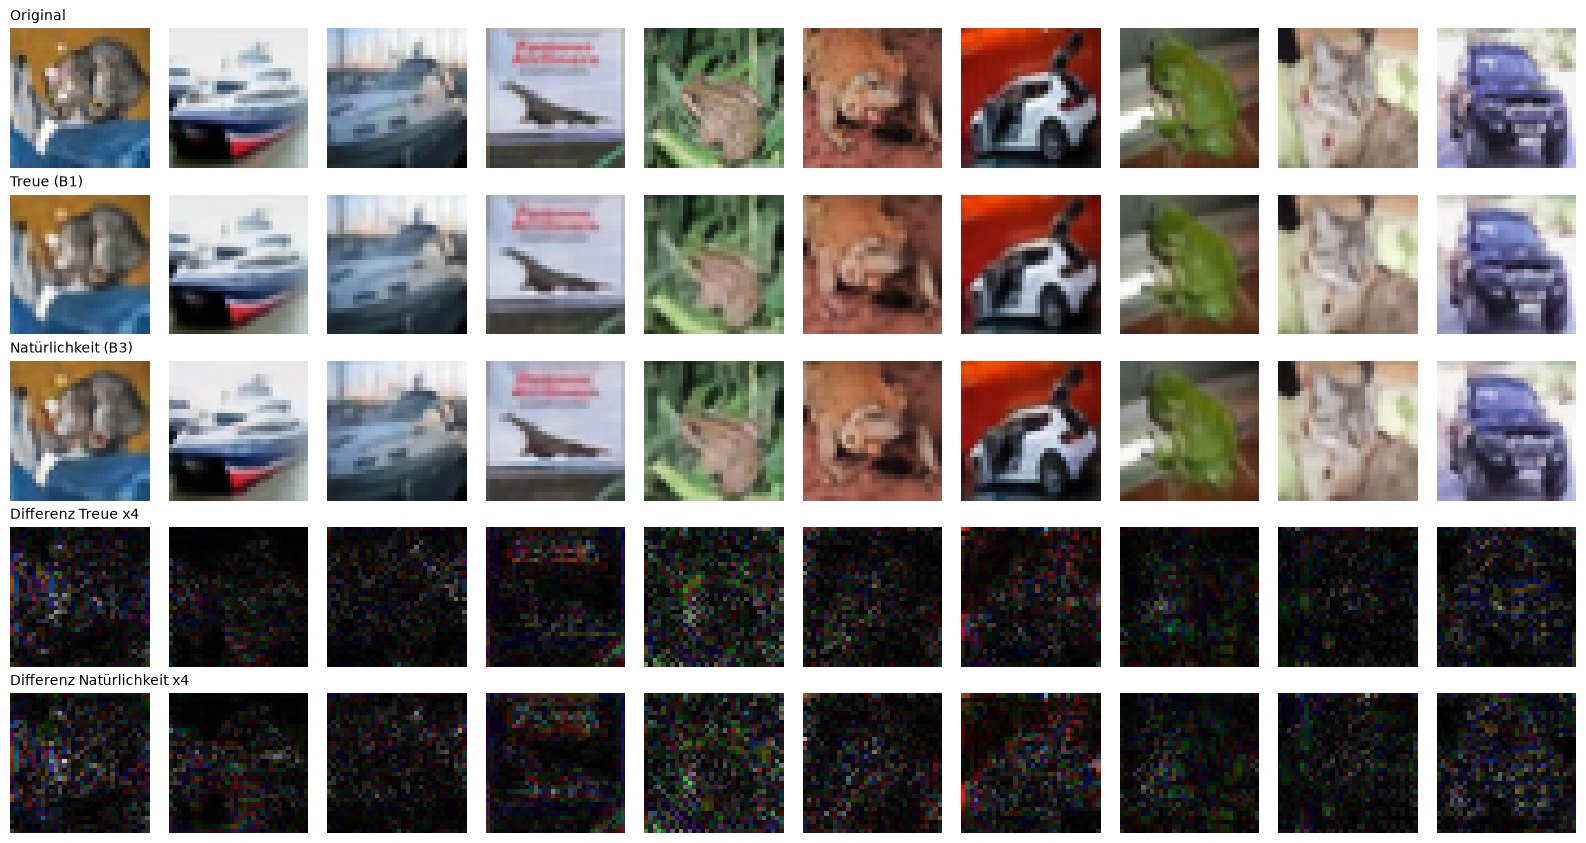

In [12]:
rows = [
    ("Original", x_test),
    (f"Treue ({FIDELITY_TAG})", predictions),
    (f"Natürlichkeit ({NATURAL_TAG})", predictions_natural),
    ("Differenz Treue x4", np.clip(np.abs(x_test - predictions) * 4, 0, 1)),
    ("Differenz Natürlichkeit x4", np.clip(np.abs(x_test - predictions_natural) * 4, 0, 1)),
]
n = 10
fig, axes = plt.subplots(len(rows), n, figsize=(n * 1.6, len(rows) * 1.7))
for r, (label, images) in enumerate(rows):
    for i in range(n):
        axes[r, i].imshow(np.kron(images[i], np.ones((4, 4, 1))), interpolation="nearest")
        axes[r, i].axis("off")
    axes[r, 0].set_title(label, loc="left", fontsize=10)
fig.tight_layout()
plt.show()

### 4b. Messen

Alle Werte stammen vom Testset mit 10.000 Bildern und aus den gespeicherten Ergebnissen der Läufe. Die Zeilen für `B1` und den Natürlichkeits-Lauf werden zur Kontrolle unten neu gerechnet.

- **KID:** Natürlichkeit über Inception-V3-Merkmale gegen die echten Testbilder. Niedriger ist besser.
- **VGG-Abstand:** normierter Merkmalsabstand. Gleiche Idee wie LPIPS, aber ohne dessen gelernte Gewichte, daher nicht LPIPS genannt.
- **Raster:** Nyquist-Leistung. Das Kriterium lautet: nicht über dem Original.

In [13]:
V5_RUNS = Path("./v5_experiments/runs")
baselines = json.loads((V5_RUNS / "baselines.json").read_text())
references = json.loads((RUNS / "references_perceptual.json").read_text())


def row(tag):
    metrics = json.loads((RUNS / f"{tag}_metrics.json").read_text())
    path = RUNS / f"{tag}_perceptual.json"
    return metrics, (json.loads(path.read_text())["test"] if path.exists() else {})


table = {"PCA 512": (baselines["pca512"], references["pca512"]),
         "v5": (exp.evaluate(models.load_model("./models/autoencoder_v5.keras", compile=False).predict(x_test, batch_size=500, verbose=0), x_test), references["v5"])}
for tag in ("B0", "B1", "B2", "B3", "B4"):
    if (RUNS / f"{tag}_metrics.json").exists():
        table[tag] = row(tag)

print(f"{'':10s}{'MSE':>9s}{'PSNR':>8s}{'SSIM':>8s}{'Raster':>9s}{'Laplace':>9s}{'KID':>9s}{'VGG':>8s}")
for label, (m, p) in table.items():
    print(f"{label:10s}{m['mse']:9.5f}{m['psnr']:8.2f}{m['ssim']:8.3f}{m['nyquist_power']:9.4f}{m['sharpness']:9.4f}"
          f"{p.get('kid', float('nan')):9.4f}{p.get('vgg_distance', float('nan')):8.4f}")
original = baselines["original"]
print(f"{'Original':10s}{'':9s}{'':8s}{'':8s}{original['nyquist_power']:9.4f}{original['sharpness']:9.4f}{references['real_train']['kid']:9.4f}")

# Kontrolle: Stimmen die gespeicherten Werte mit den geladenen Gewichten überein?
for tag, recon in ((FIDELITY_TAG, predictions), (NATURAL_TAG, predictions_natural)):
    fresh, stored = exp.evaluate(recon, x_test), table[tag][0]
    print(f"Kontrolle {tag}: MSE {fresh['mse']:.5f} gegen {stored['mse']:.5f}, SSIM {fresh['ssim']:.3f} gegen {stored['ssim']:.3f}")

                MSE    PSNR    SSIM   Raster  Laplace      KID     VGG
PCA 512     0.00102   29.93   0.948   0.0065   0.0218   0.0258  0.0809
v5          0.00216   26.66   0.903   0.0075   0.0150   0.0492  0.1557
B0          0.00091   30.42   0.956   0.0189   0.0242   0.0241  0.0667
B1          0.00077   31.12   0.963   0.0173   0.0258   0.0216  0.0575
B2          0.00076   31.21   0.962   0.0190   0.0253   0.0215  0.0526
B3          0.00089   30.49   0.958   0.0512   0.0315   0.0125  0.0642
B4          0.00086   30.65   0.959   0.0640   0.0316   0.0128  0.0572
Original                              0.0561   0.0344  -0.0000


Kontrolle B1: MSE 0.00077 gegen 0.00077, SSIM 0.963 gegen 0.963


Kontrolle B3: MSE 0.00089 gegen 0.00089, SSIM 0.958 gegen 0.958


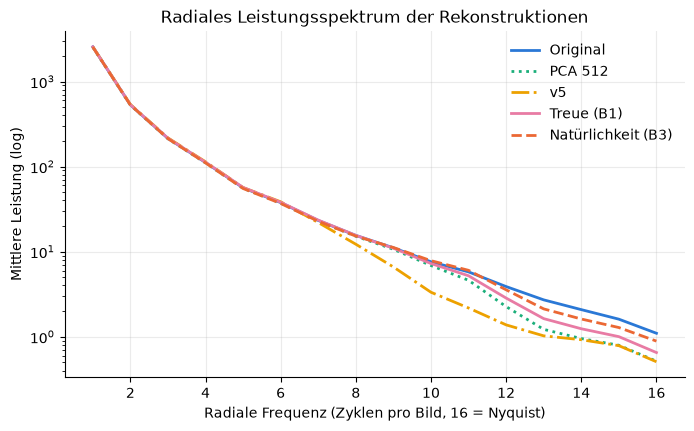

In [14]:
curves = [
    ("Original", original["spectrum"], "#2a78d6", "-"),
    ("PCA 512", baselines["pca512"]["spectrum"], "#1baf7a", ":"),
    ("v5", table["v5"][0]["spectrum"], "#eda100", "-."),
    (f"Treue ({FIDELITY_TAG})", table[FIDELITY_TAG][0]["spectrum"], "#e87ba4", "-"),
    (f"Natürlichkeit ({NATURAL_TAG})", table[NATURAL_TAG][0]["spectrum"], "#eb6834", "--"),
]
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, spectrum, color, style in curves:
    ax.plot(range(1, 17), spectrum[1:], label=label, color=color, linestyle=style, linewidth=2)
ax.set_yscale("log")
ax.set_xlabel("Radiale Frequenz (Zyklen pro Bild, 16 = Nyquist)")
ax.set_ylabel("Mittlere Leistung (log)")
ax.set_title("Radiales Leistungsspektrum der Rekonstruktionen")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

### 4c. Schärfer wirken: Unsharp Mask

Ein klassischer Filter hebt Kanten an: `Bild + Stärke × (Bild − weichgezeichnetes Bild)`. Er fügt keine Information hinzu. Berechnet mit `phase4a.py`.

Modell, Stärke          MSE    SSIM   Raster  Laplace      KID     VGG
B1, 0.5             0.00147   0.945   0.0436   0.0484   0.0123  0.0711
B1, 1.0             0.00327   0.904   0.1221   0.0765   0.0095  0.0974
B1, 2.0             0.00878   0.809   0.4751   0.1400   0.0119  0.1540
B3, 0.5             0.00180   0.935   0.1252   0.0612   0.0063  0.0814
B3, 1.0             0.00391   0.889   0.2897   0.0979   0.0057  0.1103
B3, 2.0             0.01004   0.789   0.8789   0.1784   0.0112  0.1697


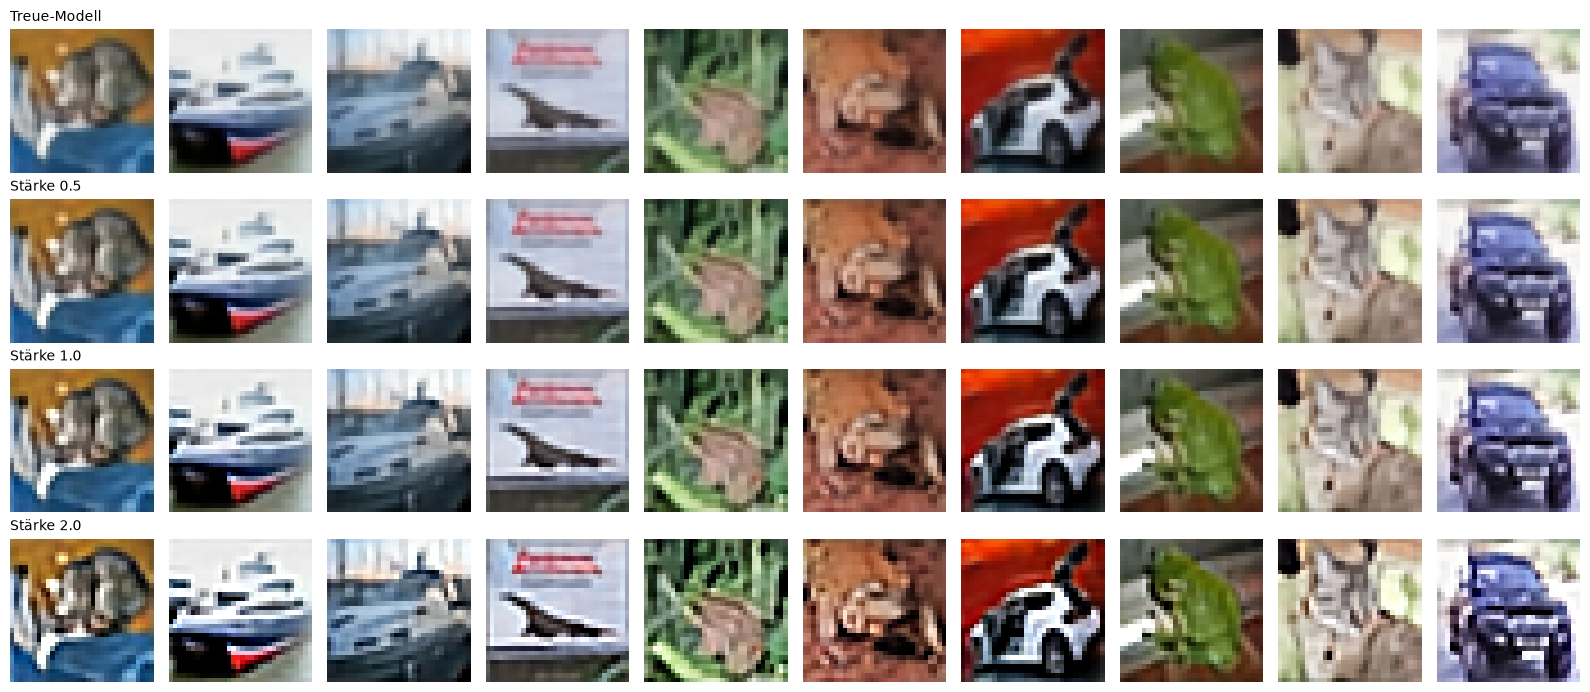

In [15]:
print(f"{'Modell, Stärke':18s}{'MSE':>9s}{'SSIM':>8s}{'Raster':>9s}{'Laplace':>9s}{'KID':>9s}{'VGG':>8s}")
for tag in (FIDELITY_TAG, NATURAL_TAG):
    for amount, m in json.loads((RUNS / f"{tag}_unsharp.json").read_text()).items():
        print(f"{tag + ', ' + amount:18s}{m['mse']:9.5f}{m['ssim']:8.3f}{m['nyquist_power']:9.4f}{m['sharpness']:9.4f}{m['kid']:9.4f}{m['vgg_distance']:8.4f}")
samples = np.load(RUNS / "B1_unsharp_first10.npz")
fig, axes = plt.subplots(len(samples.files) + 1, 10, figsize=(16, 7))
for r, (label, images) in enumerate([("Treue-Modell", predictions[:10])] + [(f"Stärke {k}", samples[k]) for k in samples.files]):
    for i in range(10):
        axes[r, i].imshow(np.kron(images[i], np.ones((4, 4, 1))), interpolation="nearest")
        axes[r, i].axis("off")
    axes[r, 0].set_title(label, loc="left", fontsize=10)
fig.tight_layout()
plt.show()

### 4d. Schärfer als das Original: Real-ESRGAN

Ein fertiges Super-Resolution-Modell (BSD-3-Clause, Xintao Wang) vergrößert von 32×32 auf 128×128, berechnet mit `phase4b_sr.py` in einer eigenen PyTorch-Umgebung.

**Die Details sind erfunden.** Zu CIFAR-10 gibt es keine höher aufgelöste Fassung, daher lässt sich nicht messen, ob sie stimmen. Die rote Schrift auf Bild 4 zeigt das gut: Sie wird scharf, aber unleserlich.

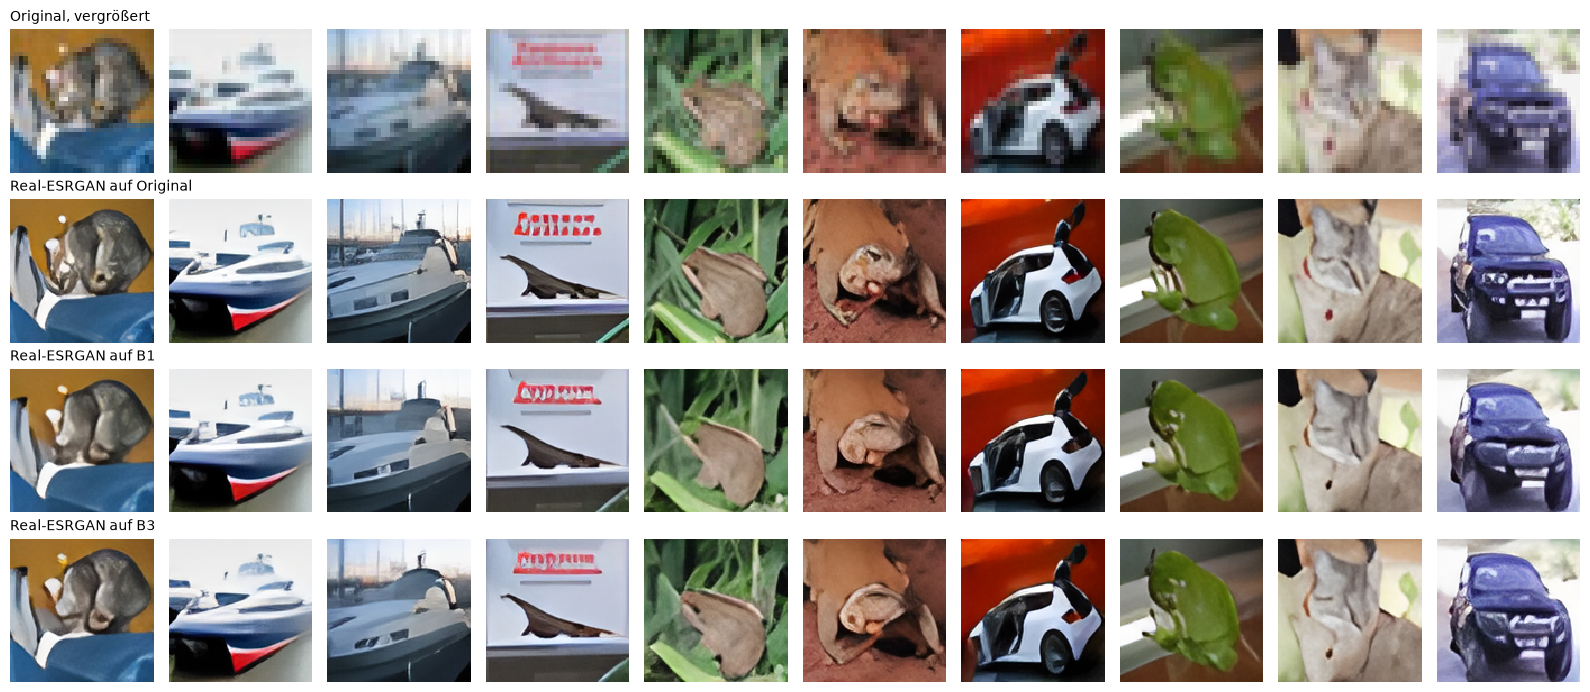

In [16]:
sr_rows = [("Original, vergrößert", np.kron(np.load(RUNS / "sr_input_original.npy"), np.ones((4, 4, 1)))),
           ("Real-ESRGAN auf Original", np.load(RUNS / "sr_output_original.npy")),
           (f"Real-ESRGAN auf {FIDELITY_TAG}", np.load(RUNS / "sr_output_B1.npy")),
           (f"Real-ESRGAN auf {NATURAL_TAG}", np.load(RUNS / f"sr_output_{NATURAL_TAG}.npy"))]
fig, axes = plt.subplots(len(sr_rows), 10, figsize=(16, 7))
for r, (label, images) in enumerate(sr_rows):
    for i in range(10):
        axes[r, i].imshow(images[i], interpolation="nearest")
        axes[r, i].axis("off")
    axes[r, 0].set_title(label, loc="left", fontsize=10)
fig.tight_layout()
plt.show()

## 5. Einbetten mit dem Encoder <a name="encode"></a>

In [17]:
# Beispielbilder kodieren
# v5: Das räumliche 8x8xC-Embedding wird für die Auswertung flach gemacht.
embeddings = encoder.predict(example_images, verbose=0).reshape(len(example_images), -1)

In [18]:
# Einige Beispiele der Embeddings (die ersten 5 von EMBEDDING_DIM Werten)
print(embeddings[:10, :5])


[[ 1.5808885  -1.2308316  -3.1297956  -1.4986528  -1.5641203 ]
 [-5.0342045  -0.08611459 -3.616809    3.8669596   0.2220975 ]
 [-3.7711093   0.02245382  0.09696525  1.9388553   1.9939659 ]
 [-2.065135   -2.6008906  -0.57981896  2.0660012  -1.0602725 ]
 [ 1.8000581  -2.1297271   0.5942542  -1.5024803   1.8012347 ]
 [ 1.7790974  -0.849534   -2.1887205   0.6839084   0.15753989]
 [ 3.0672684  -0.10744452 -6.2529407  -3.5224462  -1.3376564 ]
 [ 0.8099928  -1.7552832   1.6072657  -0.799462   -0.33568543]
 [ 3.6291163  -1.0800956   3.6264765  -3.4811592  -1.4937906 ]
 [-3.4908197  -0.28705117 -3.9027743   4.3012104   0.44764757]]


### 5a. Einen höherdimensionalen latenten Raum visualisieren

Mit `EMBEDDING_DIM = 256` lässt sich das rohe Embedding nicht mehr direkt als Streudiagramm darstellen; zwei beliebige von 256 Achsen zu plotten, wäre genauso wenig aussagekräftig wie zuvor. Stattdessen projizieren wir das gesamte Embedding **nur zur Visualisierung** auf 2D, mit zwei Standardverfahren:

- **PCA**: eine schnelle, lineare Projektion auf die 2 Richtungen mit der größten Varianz. Gut als Plausibilitätsprüfung, kann aber nichtlineare Clusterstrukturen verbergen.
- **t-SNE**: eine nichtlineare Projektion, die gezielt lokale Nachbarschaften zu erhalten versucht. Sie zeigt tatsächlich vorhandene Clusterstrukturen im Embedding deshalb viel besser, ist aber langsamer und erhält globale Abstände nicht.

Überlappen sich die Klassen selbst in der t-SNE-Projektion stark, ist das ein deutliches Zeichen, dass das Embedding selbst die Klassen schlecht trennt (und nicht nur ein Artefakt des 2D-Plots).

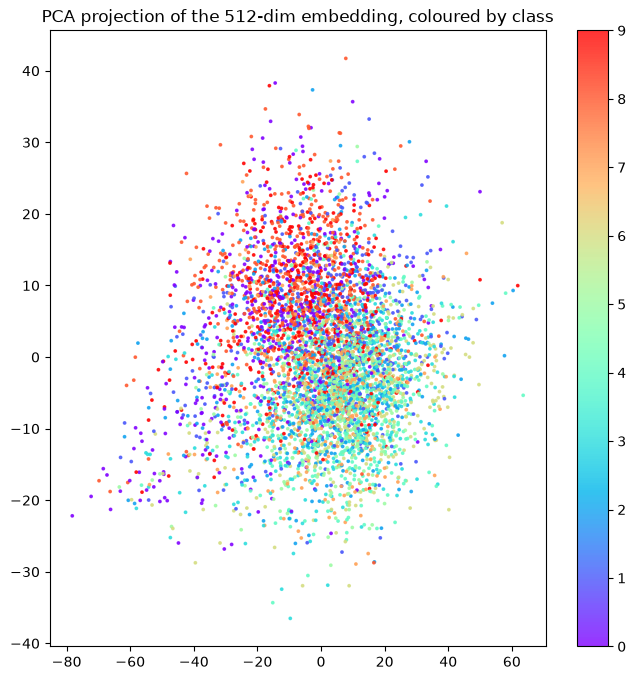

In [19]:
# PCA-Projektion des Embeddings, nach Klasse eingefärbt
pca = PCA(n_components=2)
embeddings_pca = pca.fit_transform(embeddings)

figsize = 8
plt.figure(figsize=(figsize, figsize))
scatter = plt.scatter(
    embeddings_pca[:, 0],
    embeddings_pca[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=3,
)
plt.colorbar(scatter)
plt.title(f"PCA projection of the {EMBEDDING_DIM}-dim embedding, coloured by class")
plt.show()

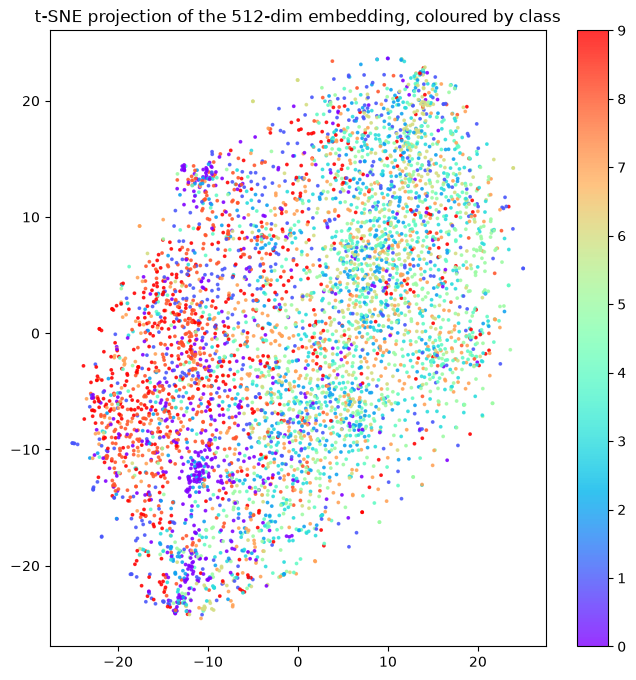

In [20]:
# t-SNE-Projektion des Embeddings, nach Klasse eingefärbt
tsne = TSNE(n_components=2, init="pca", perplexity=30, random_state=42)
embeddings_tsne = tsne.fit_transform(embeddings)

figsize = 8
plt.figure(figsize=(figsize, figsize))
scatter = plt.scatter(
    embeddings_tsne[:, 0],
    embeddings_tsne[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=3,
)
plt.colorbar(scatter)
plt.title(f"t-SNE projection of the {EMBEDDING_DIM}-dim embedding, coloured by class")
plt.show()

### 5b. Klassentrennung quantifizieren: eine k-NN-Probe

Statt die Trennung nach Augenmaß zu beurteilen, ist es aussagekräftiger, das Embedding als Merkmale für einen einfachen Klassifikator zu verwenden und die Genauigkeit auf zurückgehaltenen Daten zu messen. Trägt das Embedding tatsächlich Klasseninformation, sollte selbst ein einfacher k-NN-Klassifikator das Raten (10 % bei 10 ausgeglichenen Klassen) deutlich schlagen. Schlägt er es kaum, ist das Embedding nicht klassentrennend, wie auch immer es im 2D-Plot aussieht, und kein Plot ändert daran etwas. Ist Klassentrennung tatsächlich das Ziel, muss sich das Trainingsziel selbst ändern (z. B. durch einen überwachten oder kontrastiven Loss).

Wir vergleichen drei Merkmalssätze auf demselben Train/Test-Split der 5000 Beispielbilder: rohe, flach gemachte Pixel, eine PCA in der Größe des Embeddings und das Embedding des Autoencoders. Die Probe trainiert nur auf 4000 Bildern, ihre Zahlen unterschätzen also, was die Merkmale auf dem vollen Trainingsset erreichen könnten.

In [21]:
labels_flat = example_labels.ravel()
pixels_flat = example_images.reshape(len(example_images), -1)

(
    emb_train, emb_test,
    pix_train, pix_test,
    y_train_knn, y_test_knn,
) = train_test_split(
    embeddings,
    pixels_flat,
    labels_flat,
    test_size=0.2,
    random_state=42,
    stratify=labels_flat,
)

pca_probe = PCA(n_components=EMBEDDING_DIM, random_state=42).fit(pix_train)
feature_sets = {
    "raw pixels": (pix_train, pix_test),
    f"{EMBEDDING_DIM}-dim PCA": (pca_probe.transform(pix_train), pca_probe.transform(pix_test)),
    f"{EMBEDDING_DIM}-dim AE embedding": (emb_train, emb_test),
}

for name, (features_train, features_test) in feature_sets.items():
    knn = KNeighborsClassifier(n_neighbors=5).fit(features_train, y_train_knn)
    accuracy = accuracy_score(y_test_knn, knn.predict(features_test))
    print(f"k-NN accuracy on {name}: {accuracy:.3f}")
print("random-guess baseline (10 classes): 0.100")


k-NN accuracy on raw pixels: 0.269
k-NN accuracy on 512-dim PCA: 0.273
k-NN accuracy on 512-dim AE embedding: 0.228
random-guess baseline (10 classes): 0.100


### Fazit: wie die Ergebnisse zu lesen sind

Alle Werte stammen vom Testset mit 10.000 Bildern, k-NN von 5.000 Bildern. Niedriger ist besser bei MSE, KID und VGG-Abstand. Beim Raster gilt: nicht über dem Original (0,0561).

| Lauf | Prüfer | MSE | SSIM | KID | VGG | Raster | k-NN |
|---|---|---|---|---|---|---|---|
| v5 | L1 + SSIM, 1.500 Schritte | 0,00216 | 0,903 | 0,0492 | 0,1557 | 0,0075 | 23,7 % |
| PCA 512 | – | 0,00102 | 0,948 | 0,0258 | 0,0809 | 0,0065 | – |
| B0 | wie v5, 11.250 Schritte | 0,00091 | 0,956 | 0,0241 | 0,0667 | 0,0189 | – |
| **B1: Treue-Modell** | B0, doppelt so breit | **0,00077** | **0,963** | 0,0216 | 0,0575 | 0,0173 | 22,8 % |
| B2 | B1 + VGG + TV | 0,00076 | 0,962 | 0,0215 | 0,0526 | 0,0190 | – |
| **B3: Natürlichkeits-Modell** | B1 + GAN (Gewicht 0,01) | 0,00089 | 0,958 | **0,0125** | 0,0642 | 0,0512 | 19,8 % |
| B4 | B1 + VGG + GAN | 0,00086 | 0,959 | 0,0128 | 0,0572 | 0,0640 | – |

**Vorab festgelegte Kriterien:**

| Kriterium | Marke | Ergebnis |
|---|---|---|
| Keine Fraktale | Raster nicht über 0,0561 | **Erfüllt** für B1 und B3, in den Zoom-Bildern kein Muster. **Verfehlt** von B4 mit 0,0640, auch wenn dort keine Fraktale zu sehen sind |
| Treue-Modell | besser als v5, Ziel PCA 512 | **Erfüllt:** B1 schlägt beide bei MSE und SSIM |
| Natürlichkeits-Modell | besser als die Treue-Variante | **Teilweise:** KID klar besser, VGG-Abstand schlechter, beim Ansehen nur ein kleiner Unterschied |

**Was die Läufe zeigen:**
- **Längeres Training war der größte Hebel in v6.** Bei gleichem Modell sinkt die MSE um 58 %. Die PCA war in v5 also nur wegen des kurzen Trainings vorn.
- **VGG bringt fast nichts.** B2 und B1 liegen bei MSE, SSIM und KID innerhalb des groben Rauschmaßes. Nur der VGG-Abstand sinkt um 9 %, und genau der wird mittrainiert.
- **Nur das GAN verbessert die KID klar,** um 42 %, bei 16 % mehr MSE. Das Gewicht ist heikel: 0,1 zerstörte das Training, 0,01 blieb stabil. Zwischenwerte wurden nicht getestet.
- **B3 und B4 sind fast gleichauf.** B4 hat den besseren VGG-Abstand. Gewählt wurde B3, weil nur es die vorab festgelegte Raster-Marke einhält.

**Schärfer als das Original (Abschnitte 4c und 4d):**
- **Unsharp Mask** senkt die KID, kostet aber Treue und erzeugt Raster. Auf B1 hält nur Stärke 0,5 die Raster-Marke ein (0,0436, KID 0,0123). Auf B3 überschreitet schon Stärke 0,5 sie (0,1252), erreicht aber die niedrigste KID bei dieser Stärke (0,0063). Stärke 1,0 senkt sie nur noch auf 0,0057.
- **Real-ESRGAN** wirkt sehr scharf, die Details sind aber erfunden. Auf CIFAR-10 lässt sich nicht prüfen, ob sie stimmen.

**Klassen:** Der Klassen-Treffer war kein Ziel von v6. Er liegt mit 22,8 % und 19,8 % unter v3 (33,8 %) und dem ursprünglichen v4 (41,9 %).

**Grenzen:** Jeder Vergleich beruht auf einem einzelnen Lauf. Nicht einzeln gemessen ist, welcher Teil der Architektur wie viel beiträgt.